In [1]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [3]:
class RNN_LSTM_Hybrid(BaseEstimator, ClassifierMixin):
    """RNN + LSTM empilhadas (combina simplicidade da RNN com complexidade da LSTM)"""

    def __init__(self,
                 rnn_hidden=16,
                 rnn_layers=1,
                 rnn_dropout=0.2,
                 lstm_hidden=16,
                 lstm_layers=1,
                 lstm_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.rnn_hidden = rnn_hidden
        self.rnn_layers = rnn_layers
        self.rnn_dropout = rnn_dropout
        self.lstm_hidden = lstm_hidden
        self.lstm_layers = lstm_layers
        self.lstm_dropout = lstm_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class RNN_LSTM_Model(nn.Module):
            def __init__(self, input_size, rnn_hidden, rnn_layers, rnn_dropout,
                         lstm_hidden, lstm_layers, lstm_dropout, fc_hidden, output_size):
                super(RNN_LSTM_Model, self).__init__()

                # Primeira camada: RNN
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=rnn_hidden,
                    num_layers=rnn_layers,
                    batch_first=True,
                    dropout=rnn_dropout if rnn_layers > 1 else 0,
                    nonlinearity='tanh'
                )

                self.rnn_dropout = nn.Dropout(rnn_dropout)

                # Segunda camada: LSTM
                self.lstm = nn.LSTM(
                    input_size=rnn_hidden,
                    hidden_size=lstm_hidden,
                    num_layers=lstm_layers,
                    batch_first=True,
                    dropout=lstm_dropout if lstm_layers > 1 else 0
                )

                self.lstm_dropout = nn.Dropout(lstm_dropout)

                # Fully connected
                fc_layers = []
                prev_size = lstm_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(rnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # RNN
                rnn_out, hidden_rnn = self.rnn(x)
                last_hidden_rnn = hidden_rnn[-1]
                x = self.rnn_dropout(last_hidden_rnn)

                # Reshape para LSTM
                x = x.unsqueeze(1)  # (batch, 1, rnn_hidden)

                # LSTM
                lstm_out, (hidden_lstm, cell) = self.lstm(x)
                last_hidden_lstm = hidden_lstm[-1]

                x = self.lstm_dropout(last_hidden_lstm)
                x = self.fc(x)
                return x

        return RNN_LSTM_Model(
            input_size=self.input_size,
            rnn_hidden=self.rnn_hidden,
            rnn_layers=self.rnn_layers,
            rnn_dropout=self.rnn_dropout,
            lstm_hidden=self.lstm_hidden,
            lstm_layers=self.lstm_layers,
            lstm_dropout=self.lstm_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
               #print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'rnn_hidden': self.rnn_hidden,
            'rnn_layers': self.rnn_layers,
            'rnn_dropout': self.rnn_dropout,
            'lstm_hidden': self.lstm_hidden,
            'lstm_layers': self.lstm_layers,
            'lstm_dropout': self.lstm_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_3627/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_rmsprop
------------------------------
TRAIN
Accuracy: 0.7062
Precision: 0.7580
Recall: 0.7062
F1: 0.7099
Kappa: 0.6455
Error Rate: 0.2938

TEST
Accuracy: 0.1791
Precision: 0.1117
Recall: 0.1791
F1: 0.0887
Kappa: 0.0352
Error Rate: 0.8209
Gap (overfitting): 0.5271

CV
Mean: 0.8090
Std: 0.0380
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



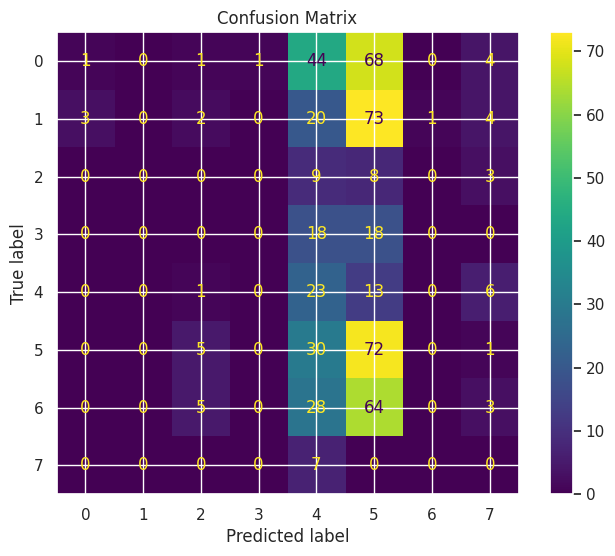

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_adam
------------------------------
TRAIN
Accuracy: 0.8102
Precision: 0.8286
Recall: 0.8102
F1: 0.8051
Kappa: 0.7677
Error Rate: 0.1898

TEST
Accuracy: 0.1772
Precision: 0.1140
Recall: 0.1772
F1: 0.0895
Kappa: 0.0163
Error Rate: 0.8228
Gap (overfitting): 0.6330

CV
Mean: 0.8011
Std: 0.0596
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



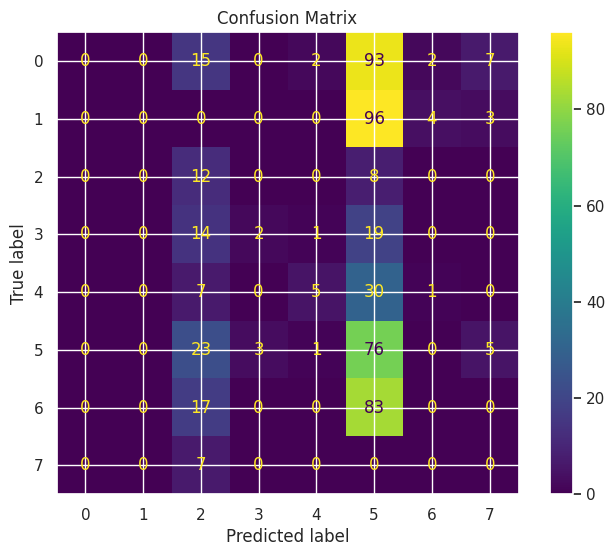

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.4027
Precision: 0.2682
Recall: 0.4027
F1: 0.3183
Kappa: 0.2388
Error Rate: 0.5973

TEST
Accuracy: 0.2295
Precision: 0.1573
Recall: 0.2295
F1: 0.1380
Kappa: 0.0376
Error Rate: 0.7705
Gap (overfitting): 0.1732

CV
Mean: 0.4112
Std: 0.0251
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



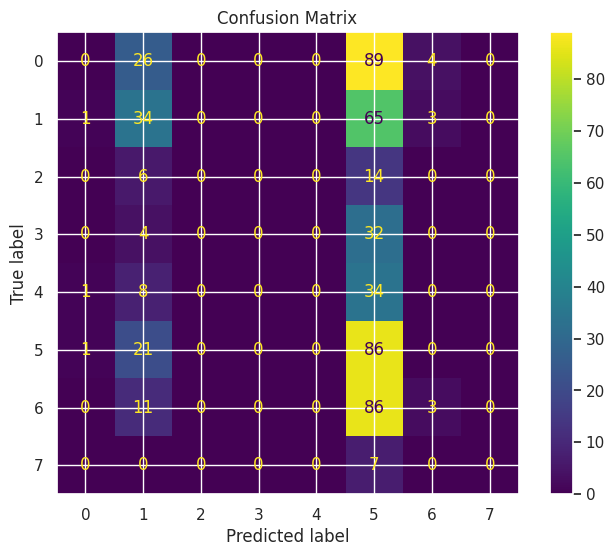

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.4540
Precision: 0.4907
Recall: 0.4540
F1: 0.4126
Kappa: 0.3091
Error Rate: 0.5460

TEST
Accuracy: 0.1903
Precision: 0.2124
Recall: 0.1903
F1: 0.1056
Kappa: 0.0182
Error Rate: 0.8097
Gap (overfitting): 0.2637

CV
Mean: 0.4527
Std: 0.0289
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



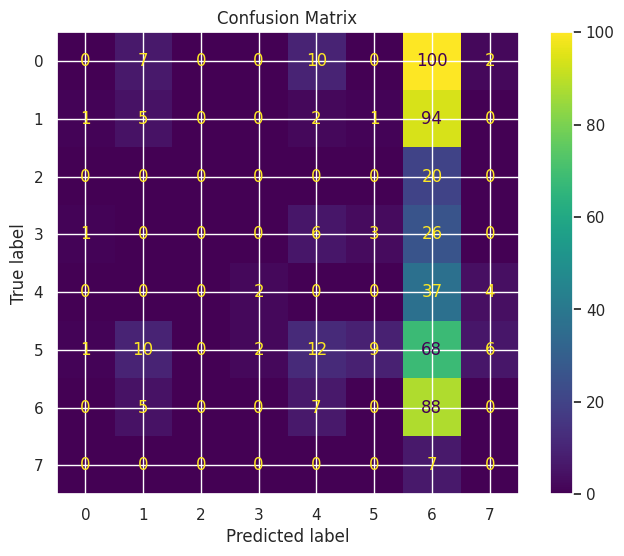

In [4]:
models_rnn_lstm = {}


models_rnn_lstm['RNN_LSTM_rmsprop'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm['RNN_LSTM_adam'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm['RNN_LSTM_sgd_momentum'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm['RNN_LSTM_adam_lowLR'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_lstm, "rnn_lstm_experiments")


/tmp/ipykernel_3627/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_1
------------------------------
TRAIN
Accuracy: 0.3971
Precision: 0.4627
Recall: 0.3971
F1: 0.3410
Kappa: 0.2388
Error Rate: 0.6029

TEST
Accuracy: 0.1884
Precision: 0.2499
Recall: 0.1884
F1: 0.0857
Kappa: 0.0203
Error Rate: 0.8116
Gap (overfitting): 0.2087

CV
Mean: 0.4286
Std: 0.0209
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



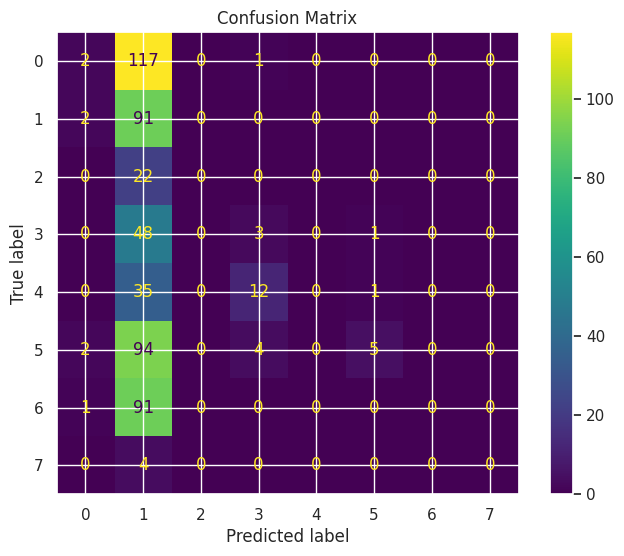

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_2
------------------------------
TRAIN
Accuracy: 0.4492
Precision: 0.3982
Recall: 0.4492
F1: 0.4103
Kappa: 0.3165
Error Rate: 0.5508

TEST
Accuracy: 0.2295
Precision: 0.3012
Recall: 0.2295
F1: 0.1827
Kappa: 0.0827
Error Rate: 0.7705
Gap (overfitting): 0.2197

CV
Mean: 0.4482
Std: 0.0311
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



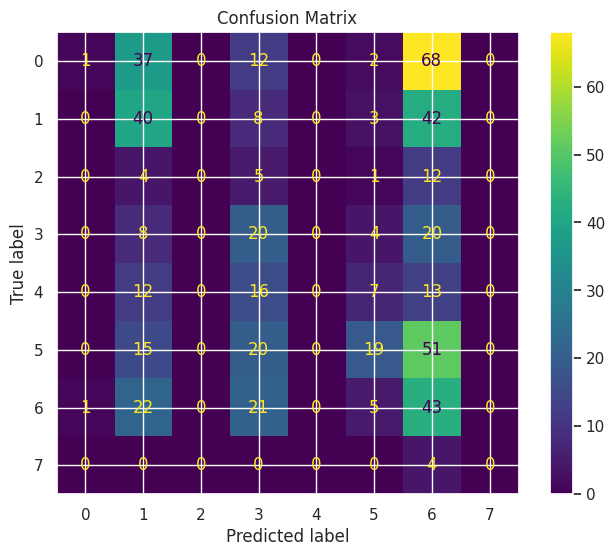

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_3
------------------------------
TRAIN
Accuracy: 0.2290
Precision: 0.0524
Recall: 0.2290
F1: 0.0853
Kappa: 0.0000
Error Rate: 0.7710

TEST
Accuracy: 0.2239
Precision: 0.0501
Recall: 0.2239
F1: 0.0819
Kappa: 0.0000
Error Rate: 0.7761
Gap (overfitting): 0.0051

CV
Mean: 0.2275
Std: 0.0242
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



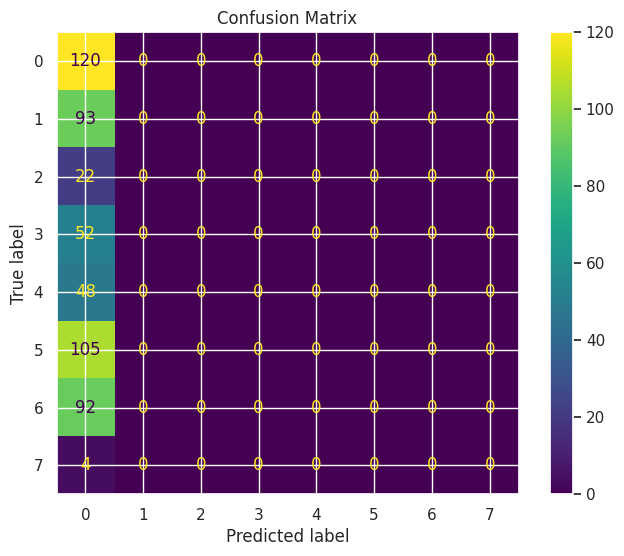

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_4
------------------------------
TRAIN
Accuracy: 0.3523
Precision: 0.2250
Recall: 0.3523
F1: 0.2742
Kappa: 0.1773
Error Rate: 0.6477

TEST
Accuracy: 0.1940
Precision: 0.1551
Recall: 0.1940
F1: 0.0921
Kappa: 0.0224
Error Rate: 0.8060
Gap (overfitting): 0.1583

CV
Mean: 0.3725
Std: 0.0302
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.3, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



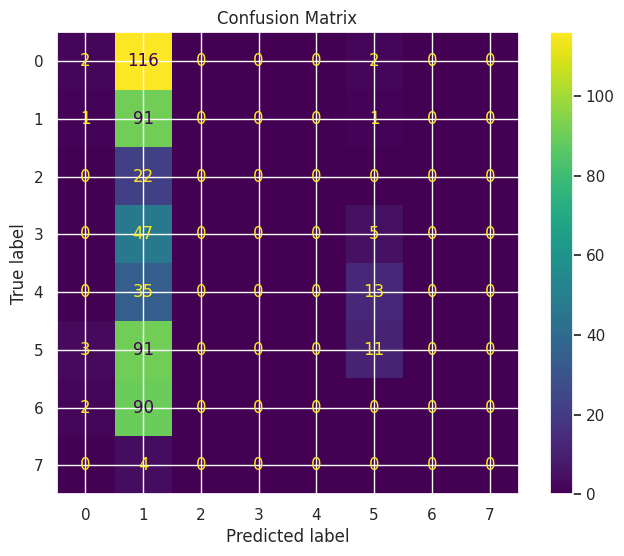

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_50
------------------------------
TRAIN
Accuracy: 0.7318
Precision: 0.7558
Recall: 0.7318
F1: 0.7318
Kappa: 0.6719
Error Rate: 0.2682

TEST
Accuracy: 0.1157
Precision: 0.0913
Recall: 0.1157
F1: 0.0493
Kappa: -0.0286
Error Rate: 0.8843
Gap (overfitting): 0.6161

CV
Mean: 0.7569
Std: 0.0319
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



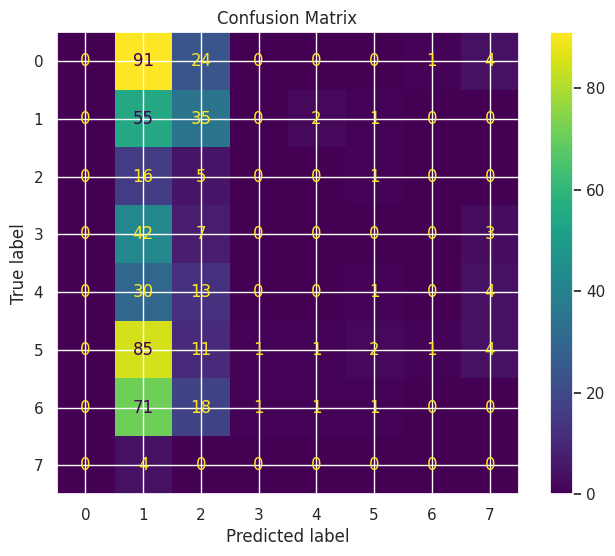

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_6
------------------------------
TRAIN
Accuracy: 0.8783
Precision: 0.8953
Recall: 0.8783
F1: 0.8795
Kappa: 0.8520
Error Rate: 0.1217

TEST
Accuracy: 0.1269
Precision: 0.0740
Recall: 0.1269
F1: 0.0864
Kappa: 0.0067
Error Rate: 0.8731
Gap (overfitting): 0.7514

CV
Mean: 0.8639
Std: 0.0491
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



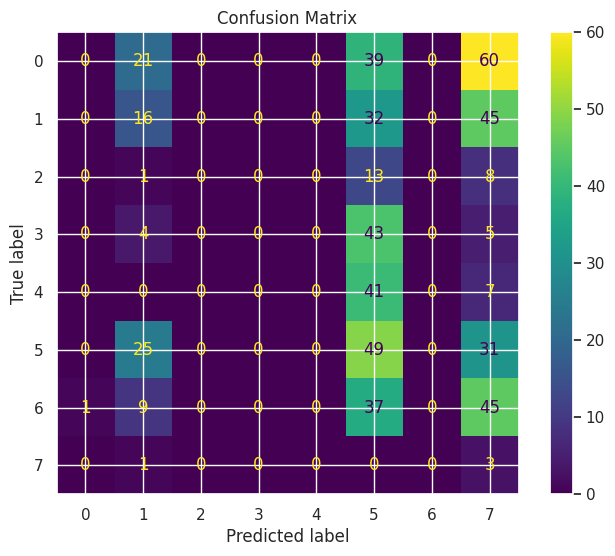

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_7
------------------------------
TRAIN
Accuracy: 0.5572
Precision: 0.5968
Recall: 0.5572
F1: 0.5496
Kappa: 0.4531
Error Rate: 0.4428

TEST
Accuracy: 0.1660
Precision: 0.2480
Recall: 0.1660
F1: 0.1210
Kappa: 0.0106
Error Rate: 0.8340
Gap (overfitting): 0.3912

CV
Mean: 0.6325
Std: 0.0431
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



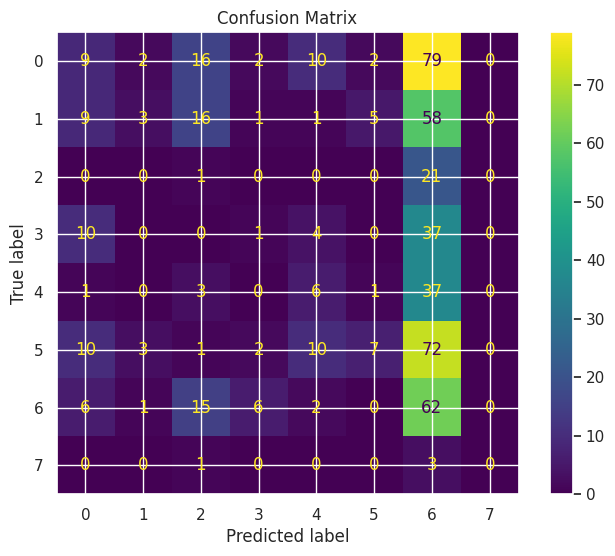

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_8
------------------------------
TRAIN
Accuracy: 0.4355
Precision: 0.4508
Recall: 0.4355
F1: 0.4197
Kappa: 0.2985
Error Rate: 0.5645

TEST
Accuracy: 0.2164
Precision: 0.1563
Recall: 0.2164
F1: 0.1289
Kappa: 0.0597
Error Rate: 0.7836
Gap (overfitting): 0.2191

CV
Mean: 0.4398
Std: 0.0195
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



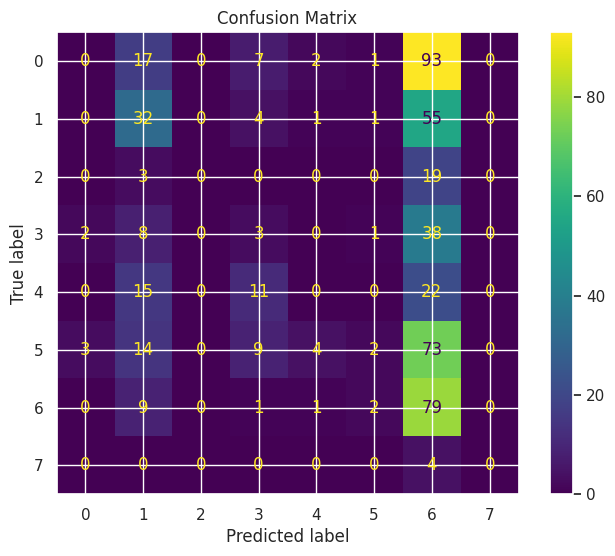

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_9
------------------------------
TRAIN
Accuracy: 0.5156
Precision: 0.5782
Recall: 0.5156
F1: 0.4914
Kappa: 0.3995
Error Rate: 0.4844

TEST
Accuracy: 0.1287
Precision: 0.2022
Recall: 0.1287
F1: 0.1084
Kappa: 0.0312
Error Rate: 0.8713
Gap (overfitting): 0.3869

CV
Mean: 0.5165
Std: 0.0270
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



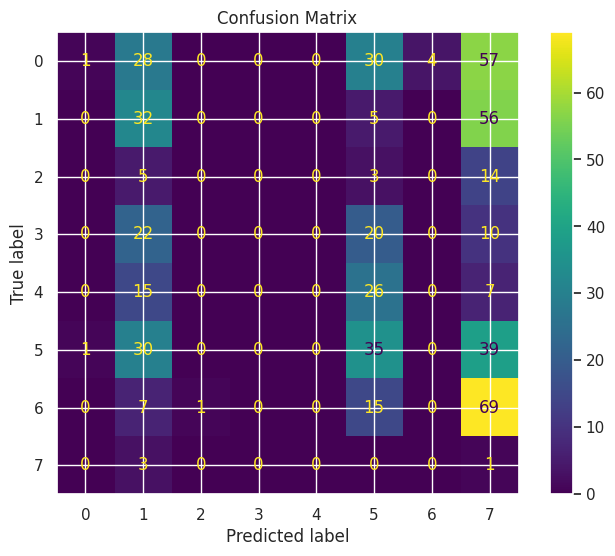

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_10
------------------------------
TRAIN
Accuracy: 0.2890
Precision: 0.2343
Recall: 0.2890
F1: 0.1860
Kappa: 0.0899
Error Rate: 0.7110

TEST
Accuracy: 0.1437
Precision: 0.1079
Recall: 0.1437
F1: 0.0849
Kappa: 0.0251
Error Rate: 0.8563
Gap (overfitting): 0.1454

CV
Mean: 0.3143
Std: 0.0236
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



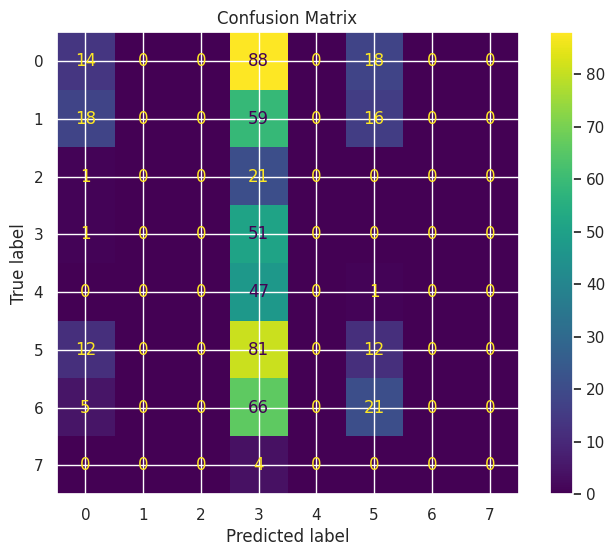

In [5]:
models_rnn_lstm_f1 = {}


# ============================================================
# 1º MELHOR: RNN_LSTM_sgd_momentum
# ============================================================


models_rnn_lstm_f1['RNN_LSTM_1'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f1['RNN_LSTM_2'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 2 camadas RNN + 2 camadas LSTM
models_rnn_lstm_f1['RNN_LSTM_3'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_rnn_lstm_f1['RNN_LSTM_4'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.3,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: RNN_LSTM_rmsprop
# ============================================================


models_rnn_lstm_f1['RNN_LSTM_50'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f1['RNN_LSTM_6'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f1['RNN_LSTM_7'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(8,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: RNN_LSTM_adam_lowLR
# ============================================================


models_rnn_lstm_f1['RNN_LSTM_8'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f1['RNN_LSTM_9'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f1['RNN_LSTM_10'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(8,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_lstm_f1, "rnn_lstm_fase_1")

/tmp/ipykernel_3627/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_adam
------------------------------
TRAIN
Accuracy: 0.3475
Precision: 0.3180
Recall: 0.3475
F1: 0.3212
Kappa: 0.1877
Error Rate: 0.6525

TEST
Accuracy: 0.1922
Precision: 0.2256
Recall: 0.1922
F1: 0.1390
Kappa: 0.0354
Error Rate: 0.8078
Gap (overfitting): 0.1553

CV
Mean: 0.4095
Std: 0.0247
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



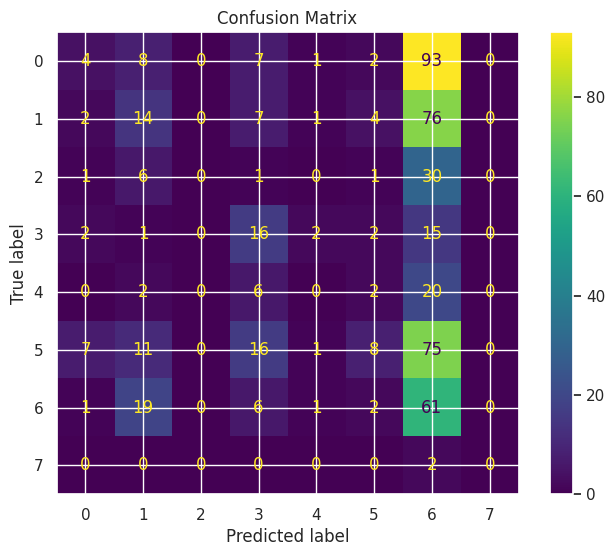

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_sgd
------------------------------
TRAIN
Accuracy: 0.3675
Precision: 0.3680
Recall: 0.3675
F1: 0.3128
Kappa: 0.2007
Error Rate: 0.6325

TEST
Accuracy: 0.1978
Precision: 0.2647
Recall: 0.1978
F1: 0.1241
Kappa: 0.0071
Error Rate: 0.8022
Gap (overfitting): 0.1697

CV
Mean: 0.4146
Std: 0.0297
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



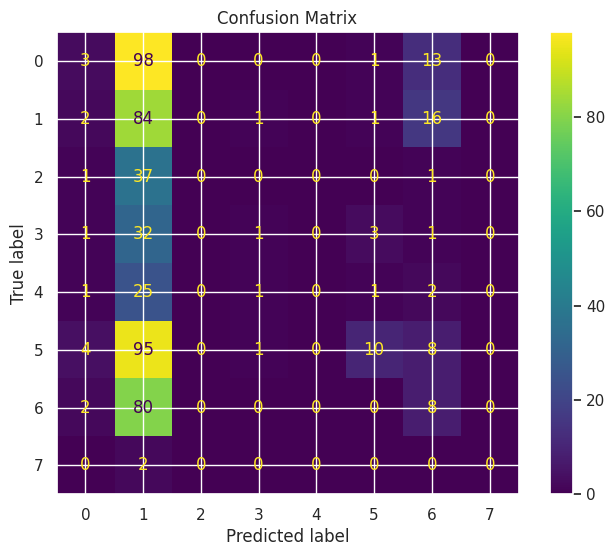


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_rmsprop
------------------------------
TRAIN
Accuracy: 0.7734
Precision: 0.7901
Recall: 0.7734
F1: 0.7726
Kappa: 0.7259
Error Rate: 0.2266

TEST
Accuracy: 0.1194
Precision: 0.5306
Recall: 0.1194
F1: 0.0947
Kappa: 0.0360
Error Rate: 0.8806
Gap (overfitting): 0.6540

CV
Mean: 0.7210
Std: 0.0883
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



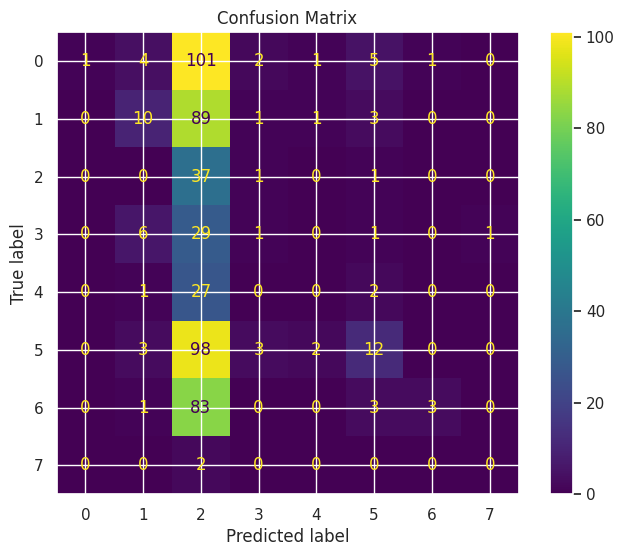

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_10
------------------------------
TRAIN
Accuracy: 0.2842
Precision: 0.1440
Recall: 0.2842
F1: 0.1837
Kappa: 0.0982
Error Rate: 0.7158

TEST
Accuracy: 0.1996
Precision: 0.0838
Recall: 0.1996
F1: 0.0860
Kappa: -0.0122
Error Rate: 0.8004
Gap (overfitting): 0.0846

CV
Mean: 0.2896
Std: 0.0153
------------------------------
Model params:
{'rnn_hidden': 5, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 5, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



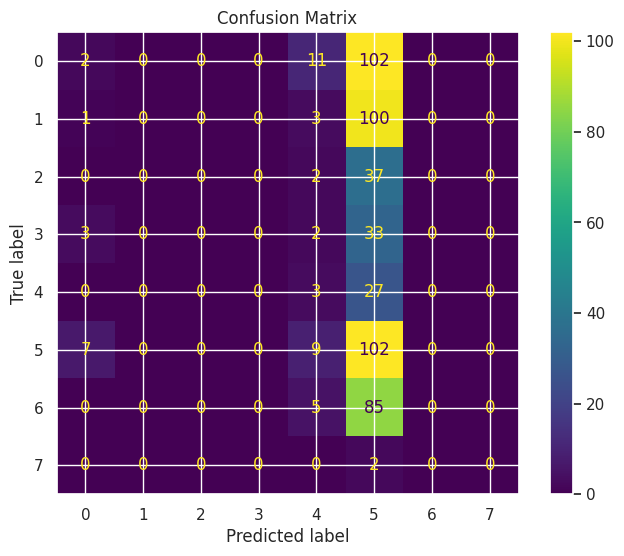

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_30
------------------------------
TRAIN
Accuracy: 0.3475
Precision: 0.3180
Recall: 0.3475
F1: 0.3212
Kappa: 0.1877
Error Rate: 0.6525

TEST
Accuracy: 0.1922
Precision: 0.2256
Recall: 0.1922
F1: 0.1390
Kappa: 0.0354
Error Rate: 0.8078
Gap (overfitting): 0.1553

CV
Mean: 0.4095
Std: 0.0247
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



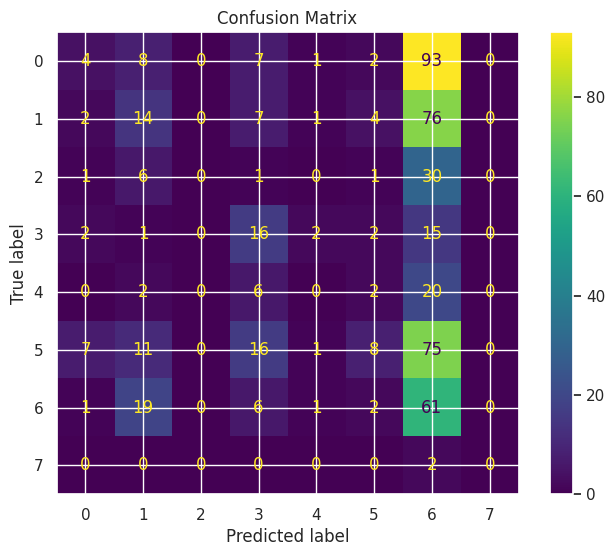

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_50
------------------------------
TRAIN
Accuracy: 0.4508
Precision: 0.4918
Recall: 0.4508
F1: 0.4278
Kappa: 0.3192
Error Rate: 0.5492

TEST
Accuracy: 0.1381
Precision: 0.2736
Recall: 0.1381
F1: 0.1311
Kappa: 0.0121
Error Rate: 0.8619
Gap (overfitting): 0.3127

CV
Mean: 0.4521
Std: 0.0255
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



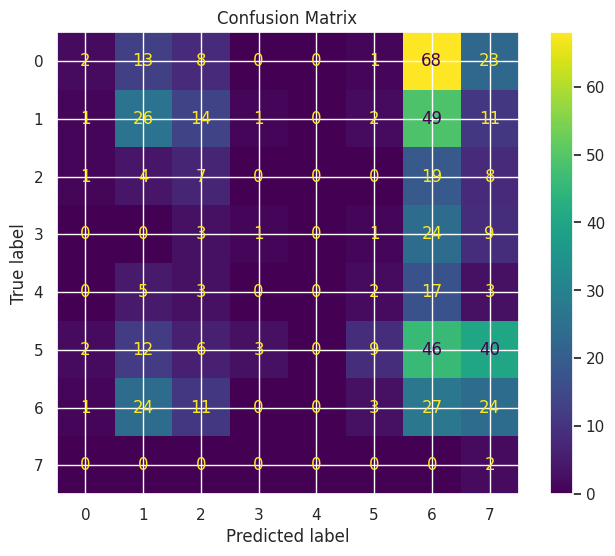

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_5016
------------------------------
TRAIN
Accuracy: 0.2618
Precision: 0.1836
Recall: 0.2618
F1: 0.1763
Kappa: 0.0951
Error Rate: 0.7382

TEST
Accuracy: 0.1530
Precision: 0.1138
Recall: 0.1530
F1: 0.0834
Kappa: 0.0039
Error Rate: 0.8470
Gap (overfitting): 0.1088

CV
Mean: 0.3008
Std: 0.0139
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



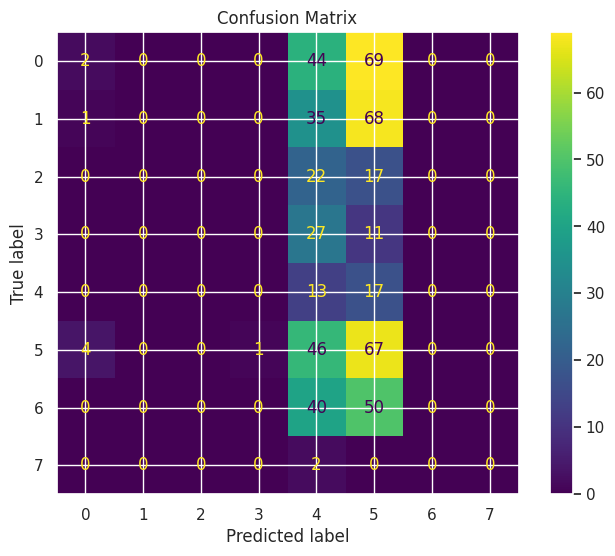

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_d0
------------------------------
TRAIN
Accuracy: 0.3475
Precision: 0.3180
Recall: 0.3475
F1: 0.3212
Kappa: 0.1877
Error Rate: 0.6525

TEST
Accuracy: 0.1922
Precision: 0.2256
Recall: 0.1922
F1: 0.1390
Kappa: 0.0354
Error Rate: 0.8078
Gap (overfitting): 0.1553

CV
Mean: 0.4095
Std: 0.0247
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



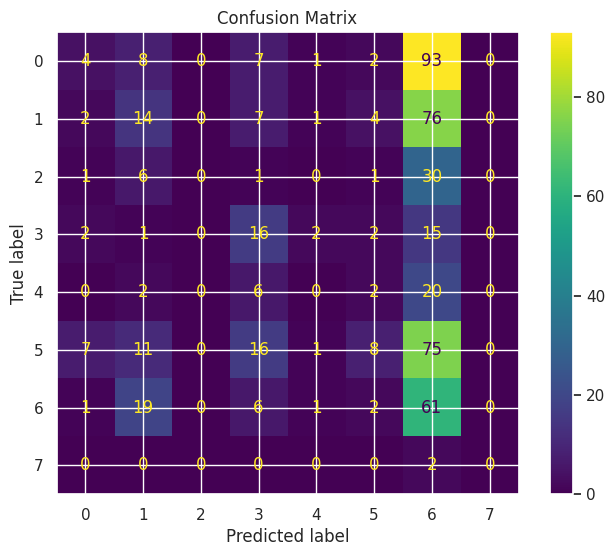

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_de-1
------------------------------
TRAIN
Accuracy: 0.3315
Precision: 0.3023
Recall: 0.3315
F1: 0.2976
Kappa: 0.1622
Error Rate: 0.6685

TEST
Accuracy: 0.1866
Precision: 0.2274
Recall: 0.1866
F1: 0.1231
Kappa: 0.0217
Error Rate: 0.8134
Gap (overfitting): 0.1449

CV
Mean: 0.3978
Std: 0.0303
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.1, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



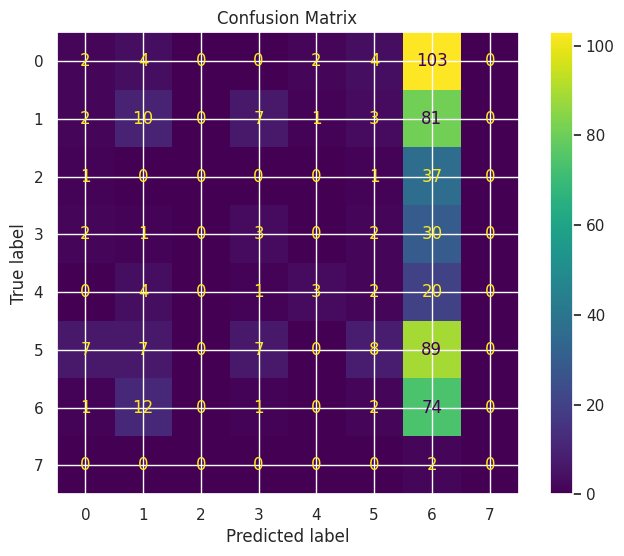

In [6]:
models_rnn_lstm_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_rnn_lstm_f2['RNN_LSTM_adam'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f2['RNN_LSTM_sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f2['RNN_LSTM_rmsprop'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================


# equivalente a hidden=10 (rnn=5, lstm=5)
models_rnn_lstm_f2['RNN_LSTM_10'] = RNN_LSTM_Hybrid(
    rnn_hidden=5, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=5, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=30 (rnn=8, lstm=8)
models_rnn_lstm_f2['RNN_LSTM_30'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=50 (rnn=16, lstm=16)
models_rnn_lstm_f2['RNN_LSTM_50'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas RNN + 2 camadas LSTM
models_rnn_lstm_f2['RNN_LSTM_5016'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_rnn_lstm_f2['RNN_LSTM_d0'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f2['RNN_LSTM_de-1'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.1,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.1, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_lstm_f2, "rnn_lstm_fase_2")

/tmp/ipykernel_3627/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_sgd
------------------------------
TRAIN
Accuracy: 0.4708
Precision: 0.3950
Recall: 0.4708
F1: 0.4150
Kappa: 0.3421
Error Rate: 0.5292

TEST
Accuracy: 0.2836
Precision: 0.1972
Recall: 0.2836
F1: 0.1772
Kappa: 0.1039
Error Rate: 0.7164
Gap (overfitting): 0.1872

CV
Mean: 0.4835
Std: 0.0316
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



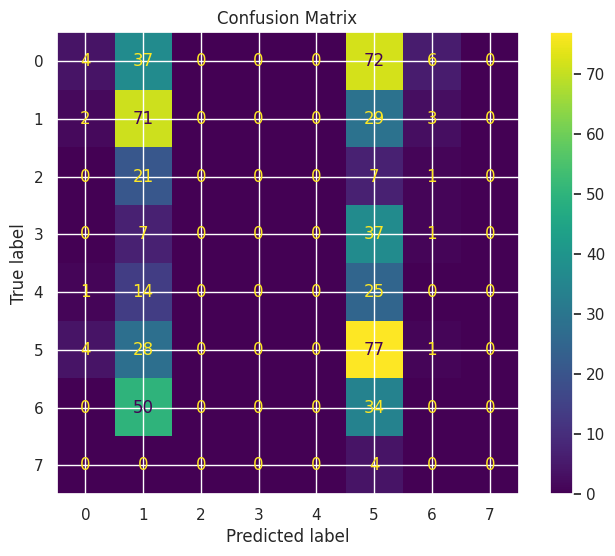

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_sgd95
------------------------------
TRAIN
Accuracy: 0.5861
Precision: 0.5770
Recall: 0.5861
F1: 0.5507
Kappa: 0.4890
Error Rate: 0.4139

TEST
Accuracy: 0.2631
Precision: 0.2463
Recall: 0.2631
F1: 0.1797
Kappa: 0.0792
Error Rate: 0.7369
Gap (overfitting): 0.3230

CV
Mean: 0.5591
Std: 0.0139
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



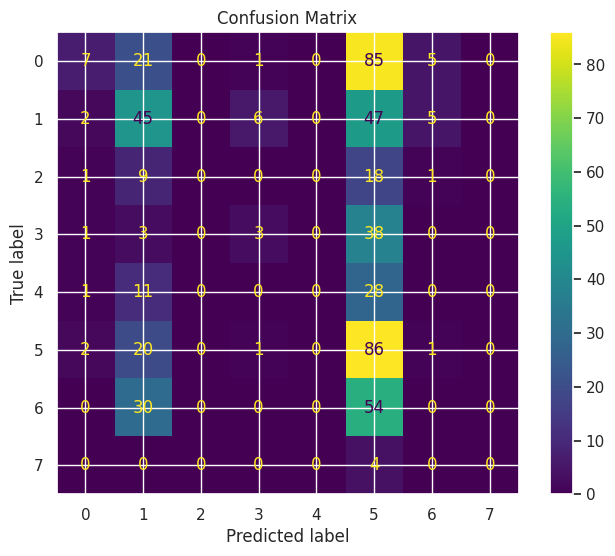

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50sgd
------------------------------
TRAIN
Accuracy: 0.4900
Precision: 0.4242
Recall: 0.4900
F1: 0.4370
Kappa: 0.3653
Error Rate: 0.5100

TEST
Accuracy: 0.2687
Precision: 0.1836
Recall: 0.2687
F1: 0.1834
Kappa: 0.0853
Error Rate: 0.7313
Gap (overfitting): 0.2213

CV
Mean: 0.4807
Std: 0.0238
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



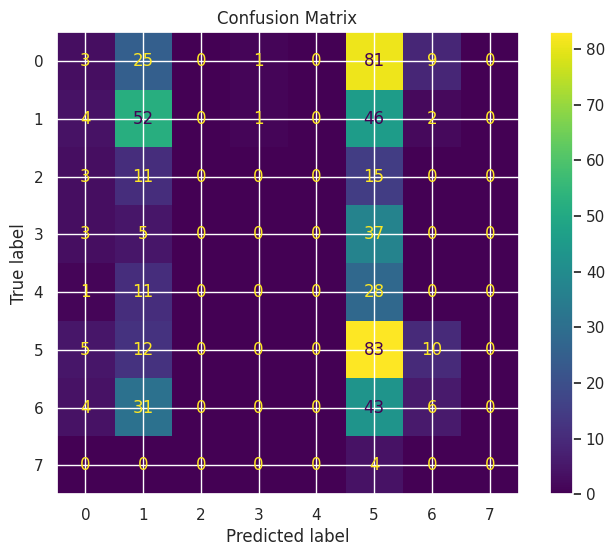

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_95
------------------------------
TRAIN
Accuracy: 0.6029
Precision: 0.5742
Recall: 0.6029
F1: 0.5760
Kappa: 0.5113
Error Rate: 0.3971

TEST
Accuracy: 0.2332
Precision: 0.2369
Recall: 0.2332
F1: 0.1368
Kappa: 0.0454
Error Rate: 0.7668
Gap (overfitting): 0.3697

CV
Mean: 0.5978
Std: 0.0405
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



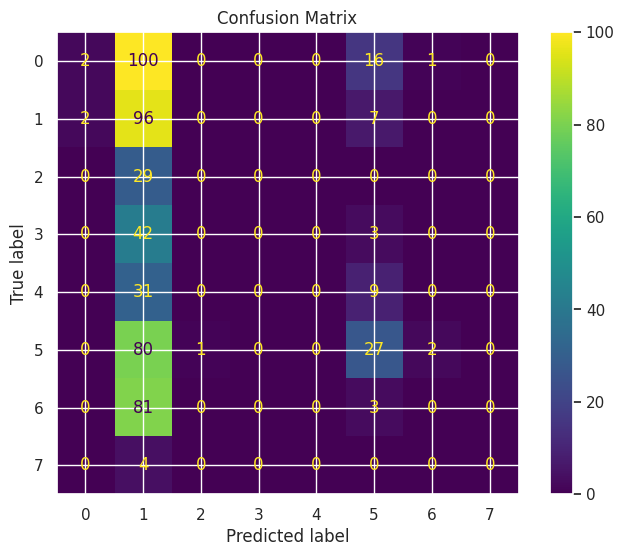

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_5016sgd
------------------------------
TRAIN
Accuracy: 0.2018
Precision: 0.0407
Recall: 0.2018
F1: 0.0677
Kappa: 0.0000
Error Rate: 0.7982

TEST
Accuracy: 0.2015
Precision: 0.1034
Recall: 0.2015
F1: 0.0859
Kappa: 0.0055
Error Rate: 0.7985
Gap (overfitting): 0.0003

CV
Mean: 0.1966
Std: 0.0198
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



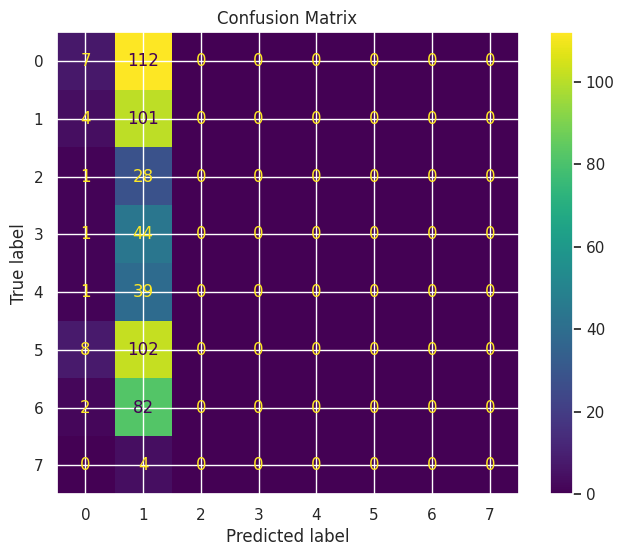

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_sgd95
------------------------------
TRAIN
Accuracy: 0.2018
Precision: 0.0407
Recall: 0.2018
F1: 0.0677
Kappa: 0.0000
Error Rate: 0.7982

TEST
Accuracy: 0.1959
Precision: 0.0384
Recall: 0.1959
F1: 0.0642
Kappa: 0.0000
Error Rate: 0.8041
Gap (overfitting): 0.0059

CV
Mean: 0.1966
Std: 0.0198
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



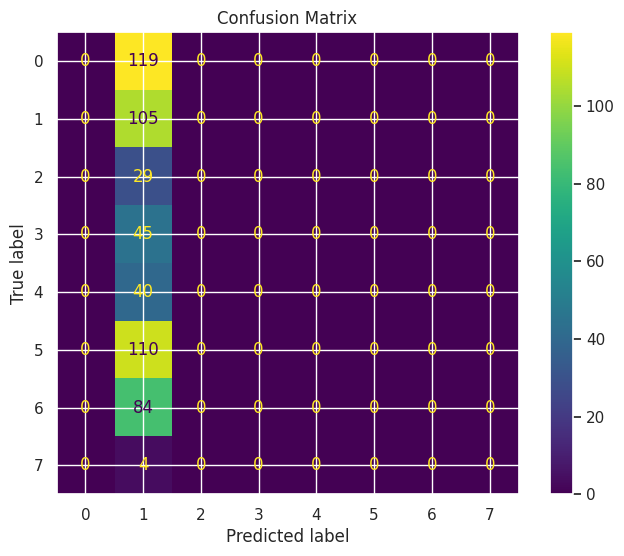

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_e-4
------------------------------
TRAIN
Accuracy: 0.4315
Precision: 0.3424
Recall: 0.4315
F1: 0.3688
Kappa: 0.2896
Error Rate: 0.5685

TEST
Accuracy: 0.2015
Precision: 0.3704
Recall: 0.2015
F1: 0.1288
Kappa: 0.0470
Error Rate: 0.7985
Gap (overfitting): 0.2301

CV
Mean: 0.4857
Std: 0.0311
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



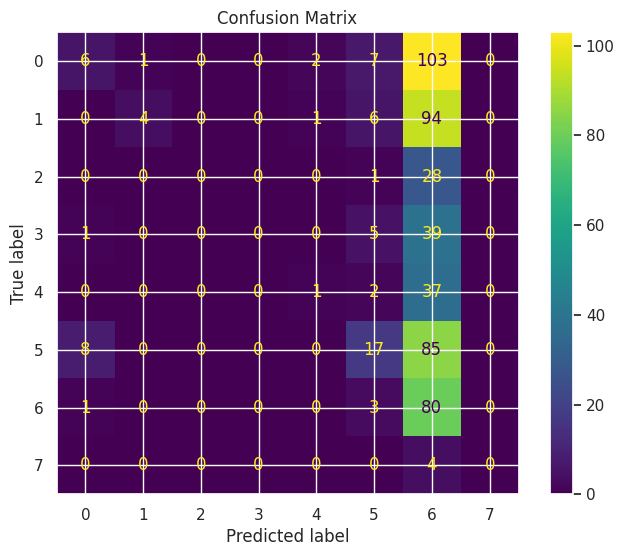

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_ae-4
------------------------------
TRAIN
Accuracy: 0.4740
Precision: 0.4149
Recall: 0.4740
F1: 0.4185
Kappa: 0.3445
Error Rate: 0.5260

TEST
Accuracy: 0.2201
Precision: 0.2995
Recall: 0.2201
F1: 0.1740
Kappa: 0.0934
Error Rate: 0.7799
Gap (overfitting): 0.2538

CV
Mean: 0.4952
Std: 0.0221
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



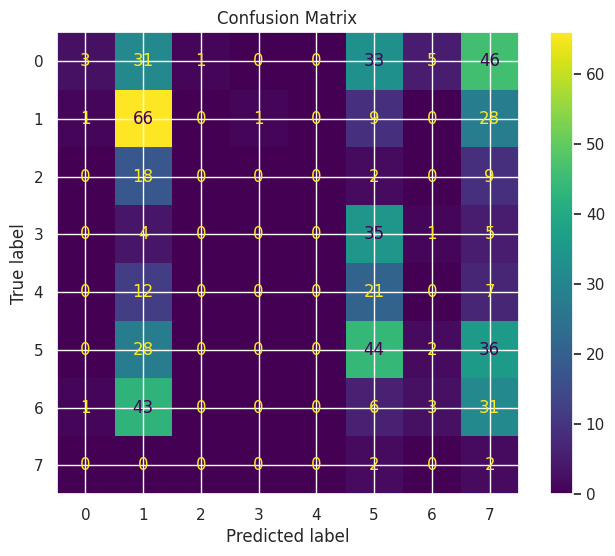

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_e-4
------------------------------
TRAIN
Accuracy: 0.2818
Precision: 0.1763
Recall: 0.2818
F1: 0.1874
Kappa: 0.0919
Error Rate: 0.7182

TEST
Accuracy: 0.2276
Precision: 0.2953
Recall: 0.2276
F1: 0.1222
Kappa: 0.0095
Error Rate: 0.7724
Gap (overfitting): 0.0542

CV
Mean: 0.3457
Std: 0.0342
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.2, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.2, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



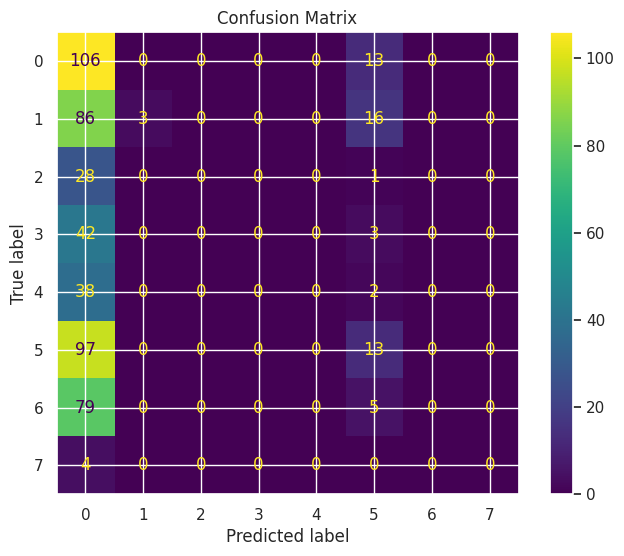

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_d2
------------------------------
TRAIN
Accuracy: 0.4556
Precision: 0.3516
Recall: 0.4556
F1: 0.3898
Kappa: 0.3191
Error Rate: 0.5444

TEST
Accuracy: 0.2836
Precision: 0.1881
Recall: 0.2836
F1: 0.1748
Kappa: 0.1041
Error Rate: 0.7164
Gap (overfitting): 0.1720

CV
Mean: 0.4728
Std: 0.0292
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



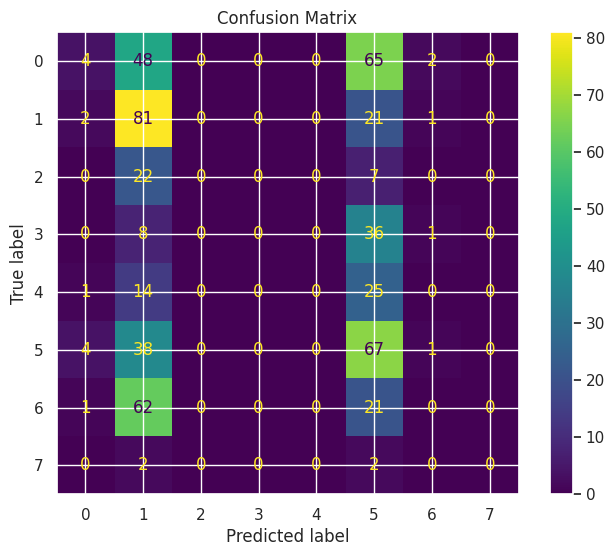

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_d3
------------------------------
TRAIN
Accuracy: 0.4620
Precision: 0.3573
Recall: 0.4620
F1: 0.3945
Kappa: 0.3269
Error Rate: 0.5380

TEST
Accuracy: 0.2799
Precision: 0.2366
Recall: 0.2799
F1: 0.1766
Kappa: 0.1002
Error Rate: 0.7201
Gap (overfitting): 0.1821

CV
Mean: 0.4661
Std: 0.0263
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.3, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



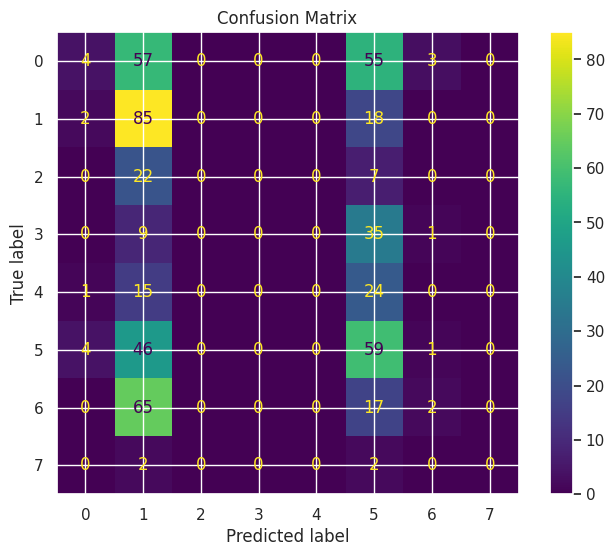

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30owLR
------------------------------
TRAIN
Accuracy: 0.2058
Precision: 0.0856
Recall: 0.2058
F1: 0.1208
Kappa: -0.0054
Error Rate: 0.7942

TEST
Accuracy: 0.2146
Precision: 0.0898
Recall: 0.2146
F1: 0.1247
Kappa: 0.0153
Error Rate: 0.7854
Gap (overfitting): -0.0088

CV
Mean: 0.2067
Std: 0.0213
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



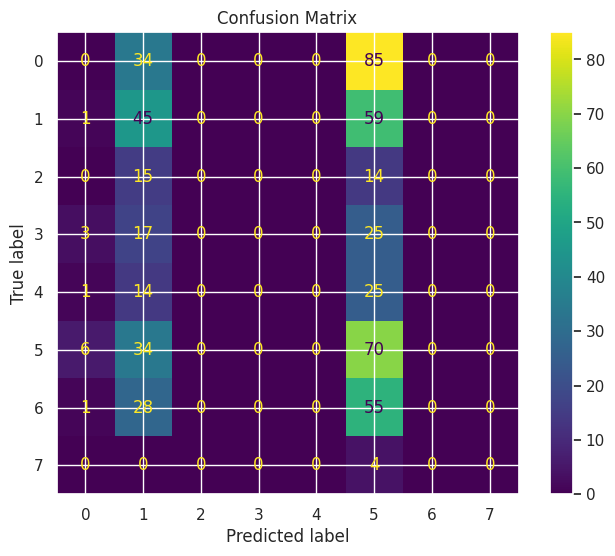

In [7]:
models_rnn_lstm_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_rnn_lstm_f3['F2_sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_sgd95'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_50sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_50_95'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_5016sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_50_16_sgd95'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_rnn_lstm_f3['F2_30_e-4'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.2,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_50_ae-4'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.2,
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_50_16_e-4'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.2,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.2, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_rnn_lstm_f3['F2_30_sgd_d2'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.2,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_30_sgd_d3'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.3,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f3['F2_30owLR'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_lstm_f3, "rnn_lstm_fase_3")



/tmp/ipykernel_3627/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3d0sgd
------------------------------
TRAIN
Accuracy: 0.4363
Precision: 0.3290
Recall: 0.4363
F1: 0.3595
Kappa: 0.2897
Error Rate: 0.5637

TEST
Accuracy: 0.2537
Precision: 0.2017
Recall: 0.2537
F1: 0.2160
Kappa: 0.0686
Error Rate: 0.7463
Gap (overfitting): 0.1826

CV
Mean: 0.4465
Std: 0.0246
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



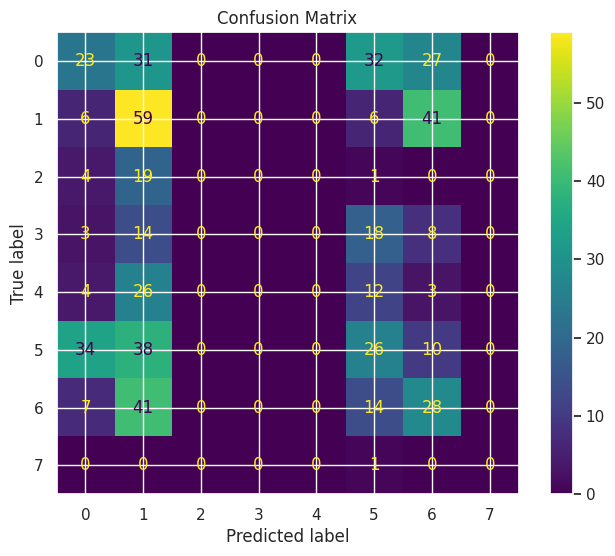

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-4_dsgd
------------------------------
TRAIN
Accuracy: 0.2218
Precision: 0.0492
Recall: 0.2218
F1: 0.0805
Kappa: 0.0000
Error Rate: 0.7782

TEST
Accuracy: 0.2239
Precision: 0.1408
Recall: 0.2239
F1: 0.1380
Kappa: 0.0175
Error Rate: 0.7761
Gap (overfitting): -0.0021

CV
Mean: 0.2280
Std: 0.0243
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



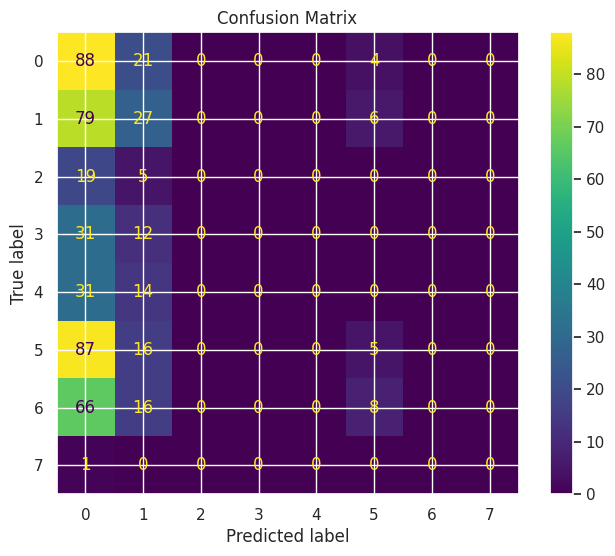

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_drsgd
------------------------------
TRAIN
Accuracy: 0.4131
Precision: 0.3162
Recall: 0.4131
F1: 0.3359
Kappa: 0.2603
Error Rate: 0.5869

TEST
Accuracy: 0.2313
Precision: 0.1677
Recall: 0.2313
F1: 0.1573
Kappa: 0.0343
Error Rate: 0.7687
Gap (overfitting): 0.1818

CV
Mean: 0.4381
Std: 0.0184
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.1, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



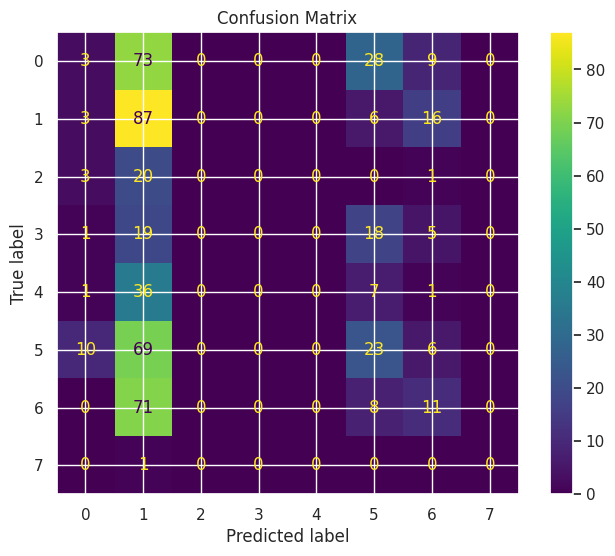

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3d2sgd
------------------------------
TRAIN
Accuracy: 0.4115
Precision: 0.3091
Recall: 0.4115
F1: 0.3248
Kappa: 0.2571
Error Rate: 0.5885

TEST
Accuracy: 0.2257
Precision: 0.1360
Recall: 0.2257
F1: 0.1340
Kappa: 0.0246
Error Rate: 0.7743
Gap (overfitting): 0.1858

CV
Mean: 0.4258
Std: 0.0161
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



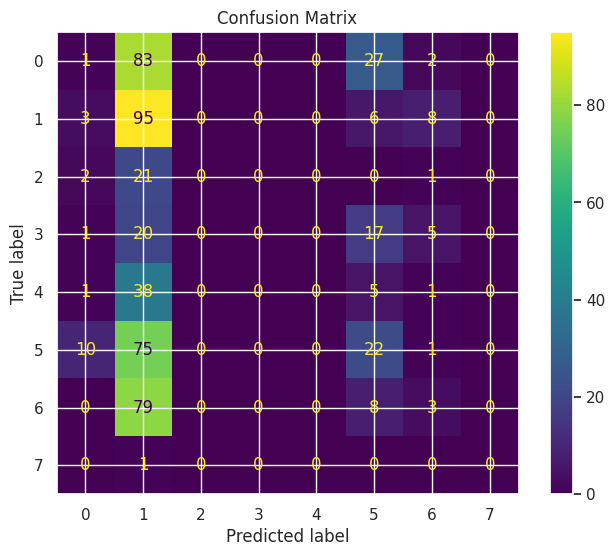

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_16e-3__sgd
------------------------------
TRAIN
Accuracy: 0.2218
Precision: 0.0492
Recall: 0.2218
F1: 0.0805
Kappa: 0.0000
Error Rate: 0.7782

TEST
Accuracy: 0.2108
Precision: 0.0444
Recall: 0.2108
F1: 0.0734
Kappa: 0.0000
Error Rate: 0.7892
Gap (overfitting): 0.0110

CV
Mean: 0.2185
Std: 0.0083
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



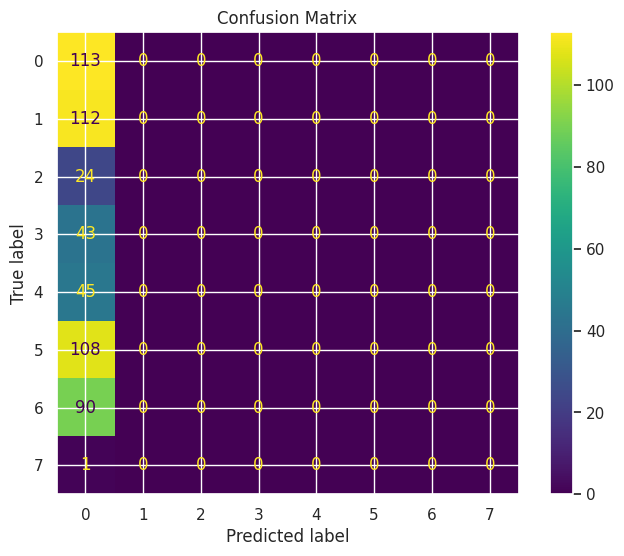

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_16e-4_gd
------------------------------
TRAIN
Accuracy: 0.2218
Precision: 0.0492
Recall: 0.2218
F1: 0.0805
Kappa: 0.0000
Error Rate: 0.7782

TEST
Accuracy: 0.2108
Precision: 0.0444
Recall: 0.2108
F1: 0.0734
Kappa: 0.0000
Error Rate: 0.7892
Gap (overfitting): 0.0110

CV
Mean: 0.2185
Std: 0.0083
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



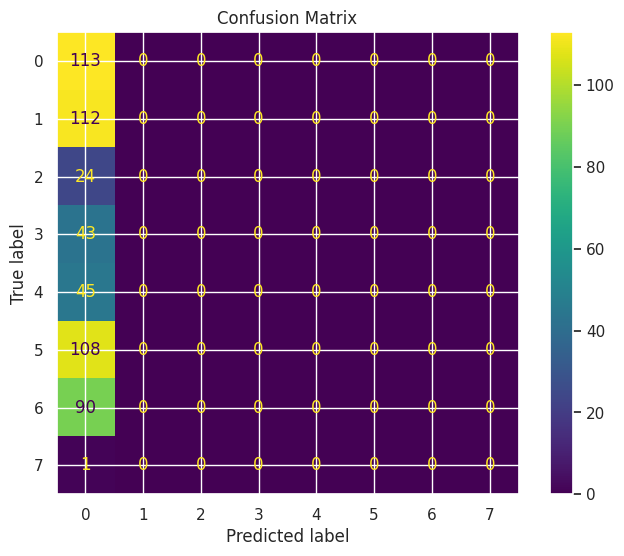

In [8]:
models_rnn_lstm_f4 = {}


# ============================================================
# 🔥 SGD com arquitetura base (30)
# ============================================================


models_rnn_lstm_f4['F3_30_lr1e-3d0sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f4['F3_30_lr1e-4_dsgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f4['F3_30_lr1e-3_drsgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.1,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.1, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f4['F3_30_lr1e-3d2sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.2,
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 SGD com arquitetura 50_16 (2 camadas)
# ============================================================


models_rnn_lstm_f4['F3_50_16e-3__sgd'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_lstm_f4['F3_50_16e-4_gd'] = RNN_LSTM_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_lstm_f4, "rnn_lstm_fase_4")

